# Exploración de Resultados de Simulación

Este notebook explora los resultados de la simulación almacenados en la carpeta `resultados/`.

## Objetivos:
1. Analizar tiempos de viaje por hora del día
2. Comparar tiempos entre diferentes días
3. Comparar tiempos por tipo de día: hábil, sábado y domingo


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# Configuración para mostrar todas las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)


## 1. Carga de Datos


In [17]:
# Cargar datos de resumen de viajes
resultados_path = Path('resultados')
df_resumen = pd.read_csv(resultados_path / 'resumen_viajes.csv')

print(f"Total de registros: {len(df_resumen)}")
print(f"\nColumnas disponibles: {list(df_resumen.columns)}")
print(f"\nPrimeras filas:")
df_resumen.head()


Total de registros: 16814

Columnas disponibles: ['fecha', 'dia', 'tipo_dia', 'hora_salida', 'hora_llegada', 'direccion', 'tiempo_total_seg', 'tiempo_total_min']

Primeras filas:


,fecha,dia,tipo_dia,hora_salida,hora_llegada,direccion,tiempo_total_seg,tiempo_total_min
0,2026-02-23,Lunes,habil,00:00,00:43,ida,2628.975689,43.82
1,2026-02-23,Lunes,habil,00:00,00:40,vuelta,2433.477356,40.56
2,2026-02-23,Lunes,habil,04:00,04:41,ida,2486.597309,41.44
3,2026-02-23,Lunes,habil,04:00,04:41,ida,2438.186014,40.64
4,2026-02-23,Lunes,habil,04:00,04:29,vuelta,1752.864382,29.21


In [18]:
# Información básica del dataset
print("Información del dataset:")
print(df_resumen.info())
print("\n" + "="*50)
print("\nEstadísticas descriptivas:")
print(df_resumen.describe())
print("\n" + "="*50)
print("\nTipos de día únicos:")
print(df_resumen['tipo_dia'].value_counts())
print("\n" + "="*50)
print("\nDías únicos:")
print(df_resumen['dia'].value_counts())
print("\n" + "="*50)
print("\nFechas únicas:")
print(sorted(df_resumen['fecha'].unique()))


Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   fecha             16814 non-null  object 
 1   dia               16814 non-null  object 
 2   tipo_dia          16814 non-null  object 
 3   hora_salida       16814 non-null  object 
 4   hora_llegada      16814 non-null  object 
 5   direccion         16814 non-null  object 
 6   tiempo_total_seg  16814 non-null  float64
 7   tiempo_total_min  16814 non-null  float64
dtypes: float64(2), object(6)
memory usage: 1.0+ MB
None


Estadísticas descriptivas:
       tiempo_total_seg  tiempo_total_min
count      16814.000000      16814.000000
mean        3295.281176         54.921361
std          603.699890         10.061671
min         1719.469799         28.660000
25%         2931.477340         48.860000
50%         3344.206699         55.740000
75%         3641.

## 2. Preparación de Datos


In [19]:
# Convertir fecha a datetime
df_resumen['fecha'] = pd.to_datetime(df_resumen['fecha'])

# Extraer hora de hora_salida (formato HH:MM)
df_resumen['hora'] = df_resumen['hora_salida'].str.split(':').str[0].astype(int)

# Crear columna de día de la semana numérico (0=Lunes, 6=Domingo)
df_resumen['dia_semana_num'] = df_resumen['fecha'].dt.dayofweek

# Asegurar que tipo_dia esté en formato consistente
df_resumen['tipo_dia'] = df_resumen['tipo_dia'].str.lower().str.strip()

print("Datos preparados:")
print(f"Rango de horas: {df_resumen['hora'].min()} - {df_resumen['hora'].max()}")
print(f"\nDistribución por tipo de día:")
print(df_resumen['tipo_dia'].value_counts())
df_resumen.head()


Datos preparados:
Rango de horas: 0 - 23

Distribución por tipo de día:
tipo_dia
habil      12010
sabado      2402
domingo     2402
Name: count, dtype: int64


,fecha,dia,tipo_dia,hora_salida,hora_llegada,direccion,tiempo_total_seg,tiempo_total_min,hora,dia_semana_num
0,2026-02-23,Lunes,habil,00:00,00:43,ida,2628.975689,43.82,0,0
1,2026-02-23,Lunes,habil,00:00,00:40,vuelta,2433.477356,40.56,0,0
2,2026-02-23,Lunes,habil,04:00,04:41,ida,2486.597309,41.44,4,0
3,2026-02-23,Lunes,habil,04:00,04:41,ida,2438.186014,40.64,4,0
4,2026-02-23,Lunes,habil,04:00,04:29,vuelta,1752.864382,29.21,4,0


## 3. Gráficos de Tiempos por Hora y por Día


In [20]:
# Agrupar por fecha y hora para calcular estadísticas
df_por_hora_dia = df_resumen.groupby(['fecha', 'dia', 'hora']).agg({
    'tiempo_total_min': ['mean', 'median', 'std', 'min', 'max', 'count']
}).reset_index()

# Aplanar nombres de columnas
df_por_hora_dia.columns = ['fecha', 'dia', 'hora', 'tiempo_promedio', 'tiempo_mediana', 
                           'tiempo_std', 'tiempo_min', 'tiempo_max', 'num_viajes']

# Agregar tipo_dia
df_por_hora_dia = df_por_hora_dia.merge(
    df_resumen[['fecha', 'tipo_dia']].drop_duplicates(), 
    on='fecha', 
    how='left'
)

print("Datos agrupados por hora y día:")
df_por_hora_dia.head(10)


Datos agrupados por hora y día:


,fecha,dia,hora,tiempo_promedio,tiempo_mediana,tiempo_std,tiempo_min,tiempo_max,num_viajes,tipo_dia
0,2026-02-23,Lunes,0,42.190000,42.190,2.305168,40.56,43.82,2,habil
1,2026-02-23,Lunes,4,36.144583,35.495,5.674903,29.21,46.66,120,habil
2,2026-02-23,Lunes,5,43.264917,41.835,11.157108,28.95,67.61,120,habil
3,2026-02-23,Lunes,6,55.069500,56.435,9.639842,41.09,67.87,120,habil
4,2026-02-23,Lunes,7,57.323000,55.985,5.905274,50.64,65.99,120,habil
5,2026-02-23,Lunes,8,55.159417,55.035,2.862147,51.04,61.58,120,habil
6,2026-02-23,Lunes,9,55.225750,54.555,1.145290,53.88,59.51,120,habil
7,2026-02-23,Lunes,10,55.050000,54.495,0.991905,53.96,58.61,120,habil
8,2026-02-23,Lunes,11,55.408750,54.900,1.156030,53.69,59.20,120,habil
9,2026-02-23,Lunes,12,54.883000,54.145,1.517602,53.37,59.47,120,habil


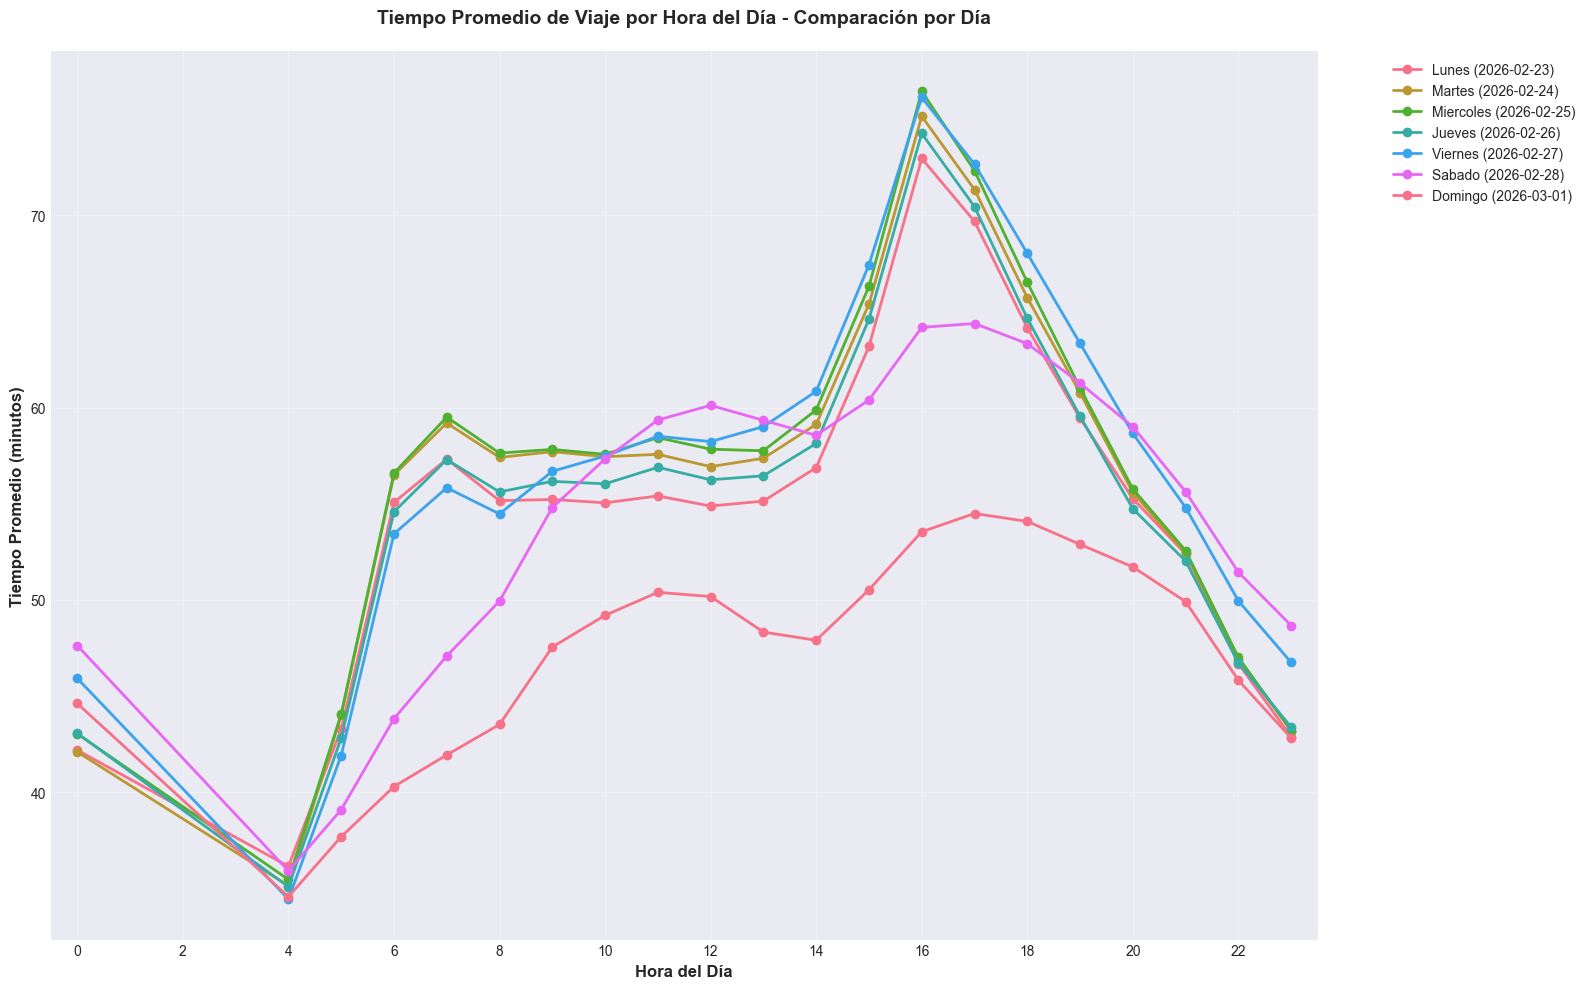

In [21]:
# Gráfico 1: Tiempo promedio por hora para cada día
fig, ax = plt.subplots(figsize=(16, 10))

# Obtener días únicos
dias_unicos = sorted(df_por_hora_dia['fecha'].unique())

# Crear gráfico de líneas para cada día
for fecha in dias_unicos:
    df_dia = df_por_hora_dia[df_por_hora_dia['fecha'] == fecha]
    dia_nombre = df_dia['dia'].iloc[0]
    ax.plot(df_dia['hora'], df_dia['tiempo_promedio'], 
            marker='o', label=f"{dia_nombre} ({fecha.strftime('%Y-%m-%d')})", 
            linewidth=2, markersize=6)

ax.set_xlabel('Hora del Día', fontsize=12, fontweight='bold')
ax.set_ylabel('Tiempo Promedio (minutos)', fontsize=12, fontweight='bold')
ax.set_title('Tiempo Promedio de Viaje por Hora del Día - Comparación por Día', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)

plt.tight_layout()
plt.show()


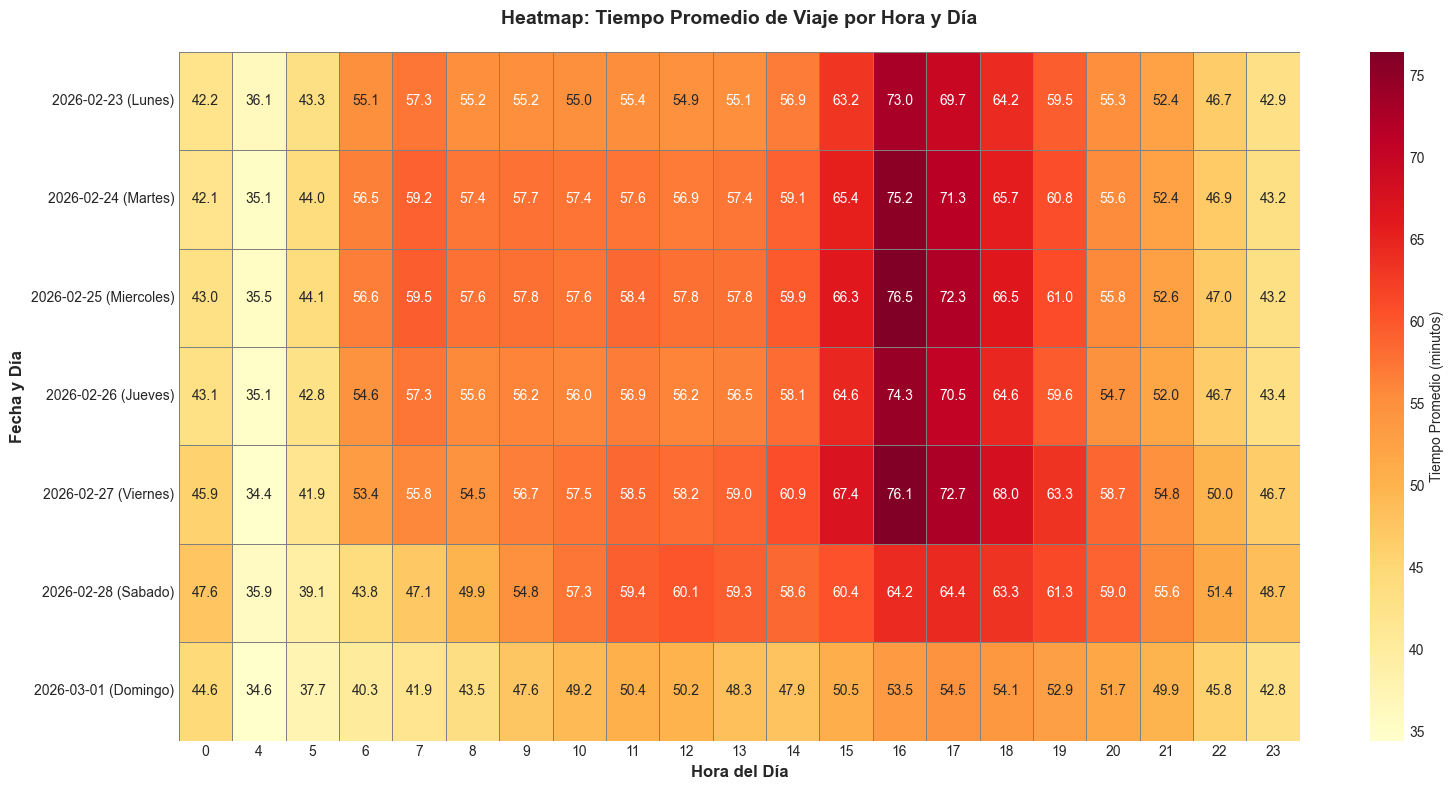

In [22]:
# Gráfico 2: Heatmap de tiempos por hora y día
fig, ax = plt.subplots(figsize=(16, 8))

# Crear matriz para el heatmap
pivot_data = df_por_hora_dia.pivot_table(
    index='fecha', 
    columns='hora', 
    values='tiempo_promedio',
    aggfunc='mean'
)

# Ordenar por fecha
pivot_data = pivot_data.sort_index()

# Crear etiquetas para el eje Y (fecha + día)
pivot_data.index = [f"{idx.strftime('%Y-%m-%d')} ({df_resumen[df_resumen['fecha']==idx]['dia'].iloc[0]})" 
                     for idx in pivot_data.index]

sns.heatmap(pivot_data, annot=True, fmt='.1f', cmap='YlOrRd', 
            cbar_kws={'label': 'Tiempo Promedio (minutos)'},
            linewidths=0.5, linecolor='gray', ax=ax)

ax.set_xlabel('Hora del Día', fontsize=12, fontweight='bold')
ax.set_ylabel('Fecha y Día', fontsize=12, fontweight='bold')
ax.set_title('Heatmap: Tiempo Promedio de Viaje por Hora y Día', 
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()


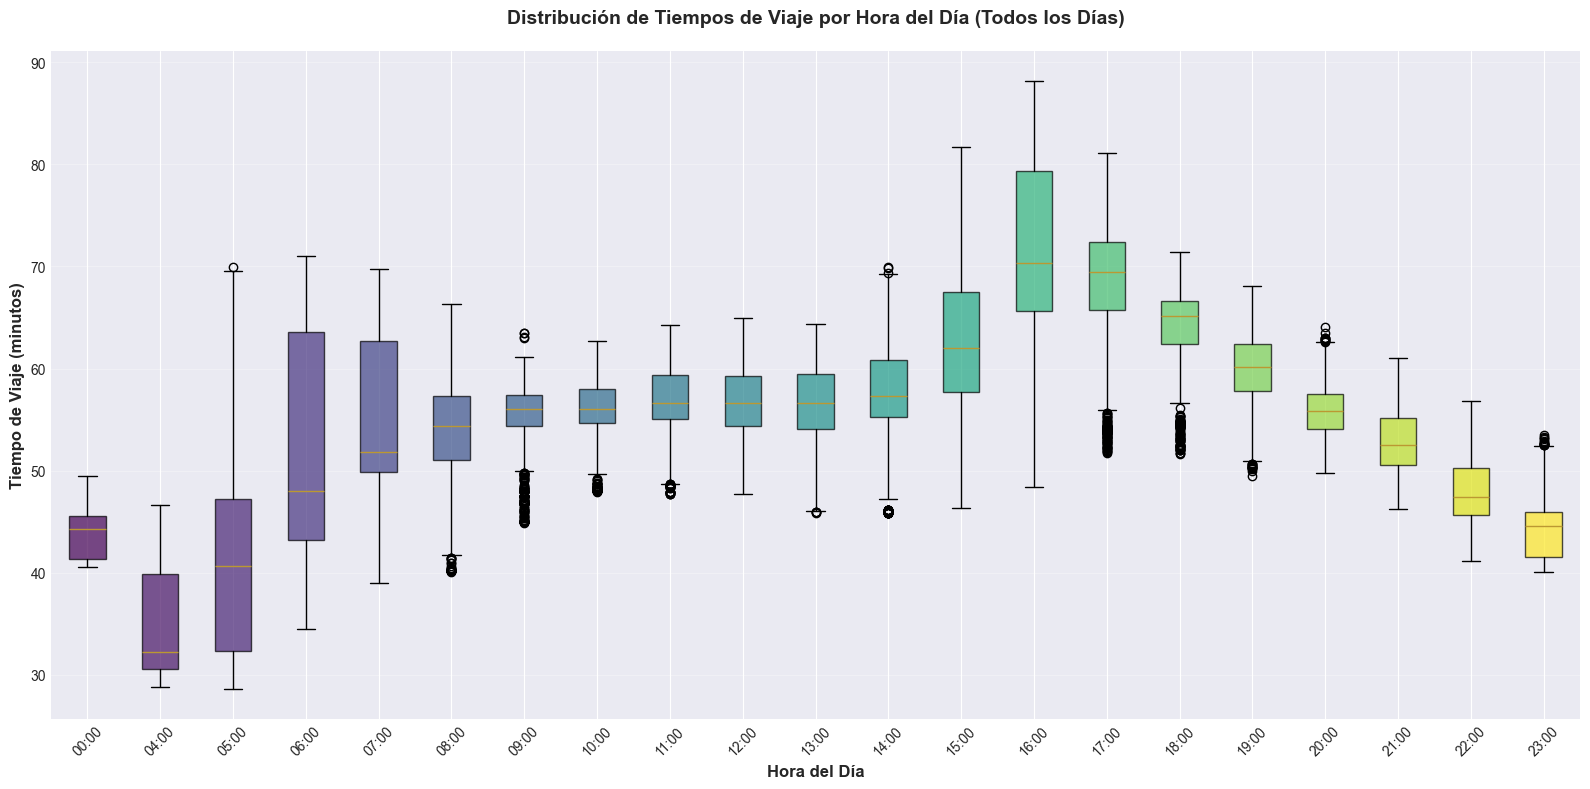

In [23]:
# Gráfico 3: Boxplot de tiempos por hora (todos los días juntos)
fig, ax = plt.subplots(figsize=(16, 8))

# Preparar datos para boxplot
data_boxplot = []
labels_boxplot = []
for hora in sorted(df_resumen['hora'].unique()):
    tiempos_hora = df_resumen[df_resumen['hora'] == hora]['tiempo_total_min'].values
    if len(tiempos_hora) > 0:
        data_boxplot.append(tiempos_hora)
        labels_boxplot.append(f"{hora:02d}:00")

bp = ax.boxplot(data_boxplot, labels=labels_boxplot, patch_artist=True)

# Colorear los boxes
colors = plt.cm.viridis(np.linspace(0, 1, len(bp['boxes'])))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_xlabel('Hora del Día', fontsize=12, fontweight='bold')
ax.set_ylabel('Tiempo de Viaje (minutos)', fontsize=12, fontweight='bold')
ax.set_title('Distribución de Tiempos de Viaje por Hora del Día (Todos los Días)', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


## 4. Gráficos por Tipo de Día (Hábil, Sábado, Domingo)


In [24]:
# Agrupar por tipo de día y hora
df_por_tipo_hora = df_resumen.groupby(['tipo_dia', 'hora']).agg({
    'tiempo_total_min': ['mean', 'median', 'std', 'min', 'max', 'count']
}).reset_index()

# Aplanar nombres de columnas
df_por_tipo_hora.columns = ['tipo_dia', 'hora', 'tiempo_promedio', 'tiempo_mediana', 
                            'tiempo_std', 'tiempo_min', 'tiempo_max', 'num_viajes']

print("Datos agrupados por tipo de día y hora:")
df_por_tipo_hora.head(10)


Datos agrupados por tipo de día y hora:


,tipo_dia,hora,tiempo_promedio,tiempo_mediana,tiempo_std,tiempo_min,tiempo_max,num_viajes
0,domingo,0,44.615000,44.615,5.069956,41.03,48.20,2
1,domingo,4,34.564250,32.105,3.900518,29.86,42.89,120
2,domingo,5,37.684000,36.615,5.797283,29.89,46.62,120
3,domingo,6,40.293167,39.750,3.956140,34.46,49.60,120
4,domingo,7,41.937917,40.695,2.683118,38.97,50.22,120
5,domingo,8,43.523667,43.520,2.398991,40.13,50.13,120
6,domingo,9,47.551667,47.455,1.843683,44.83,52.35,120
7,domingo,10,49.198750,48.375,1.459977,47.89,53.46,120
8,domingo,11,50.396250,49.205,2.286492,47.72,55.37,120
9,domingo,12,50.176750,48.750,2.702948,47.69,56.58,120


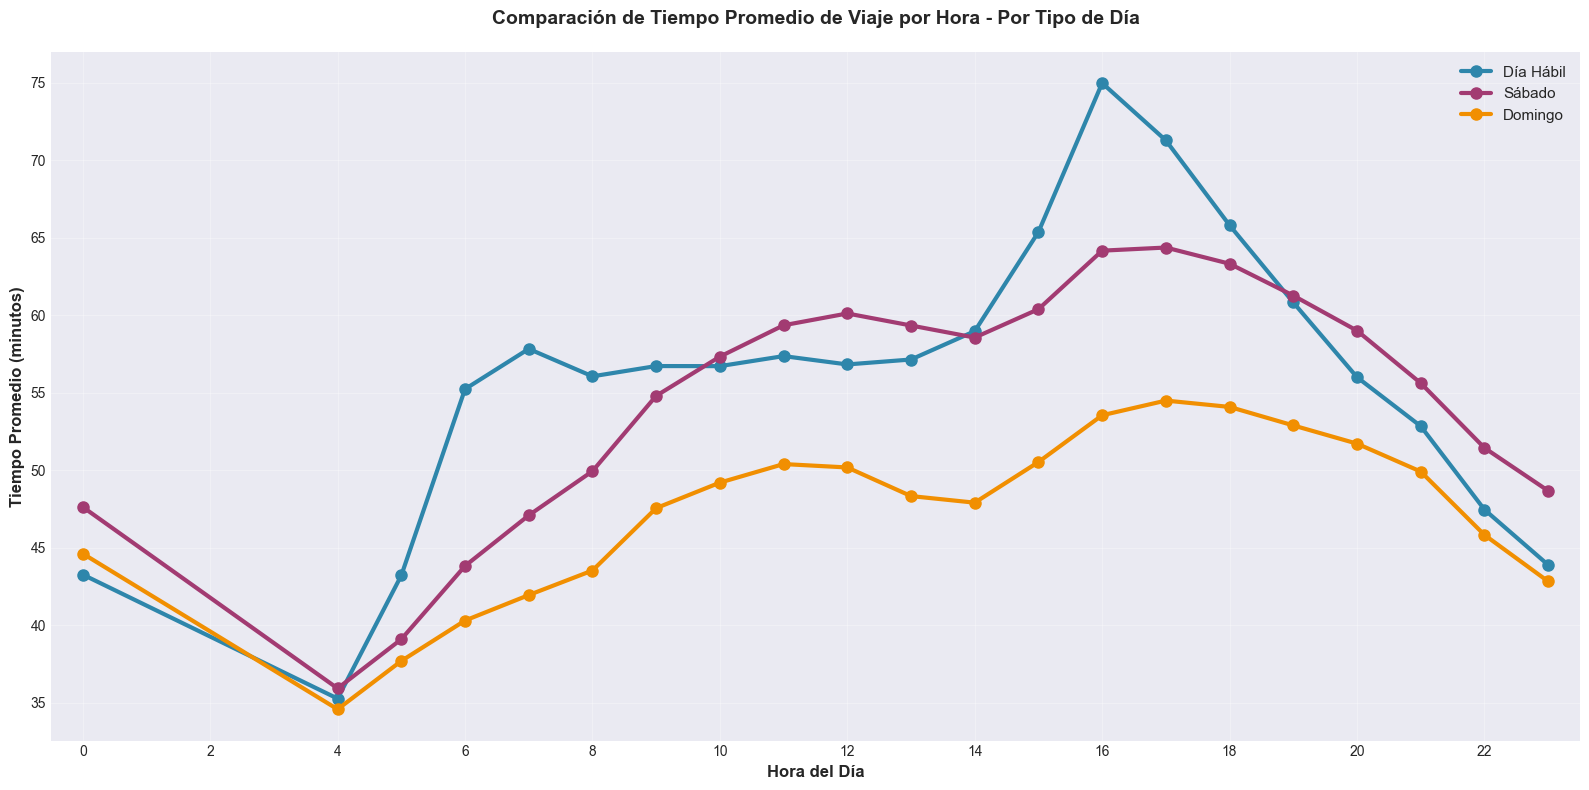

In [25]:
# Gráfico 4: Comparación de tiempos promedio por tipo de día
fig, ax = plt.subplots(figsize=(16, 8))

# Colores para cada tipo de día
colores = {'habil': '#2E86AB', 'sabado': '#A23B72', 'domingo': '#F18F01'}

for tipo_dia in ['habil', 'sabado', 'domingo']:
    df_tipo = df_por_tipo_hora[df_por_tipo_hora['tipo_dia'] == tipo_dia]
    if len(df_tipo) > 0:
        # Traducir nombre
        nombre_tipo = {'habil': 'Día Hábil', 'sabado': 'Sábado', 'domingo': 'Domingo'}[tipo_dia]
        ax.plot(df_tipo['hora'], df_tipo['tiempo_promedio'], 
                marker='o', label=nombre_tipo, 
                linewidth=3, markersize=8, color=colores.get(tipo_dia, 'gray'))

ax.set_xlabel('Hora del Día', fontsize=12, fontweight='bold')
ax.set_ylabel('Tiempo Promedio (minutos)', fontsize=12, fontweight='bold')
ax.set_title('Comparación de Tiempo Promedio de Viaje por Hora - Por Tipo de Día', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)

plt.tight_layout()
plt.show()


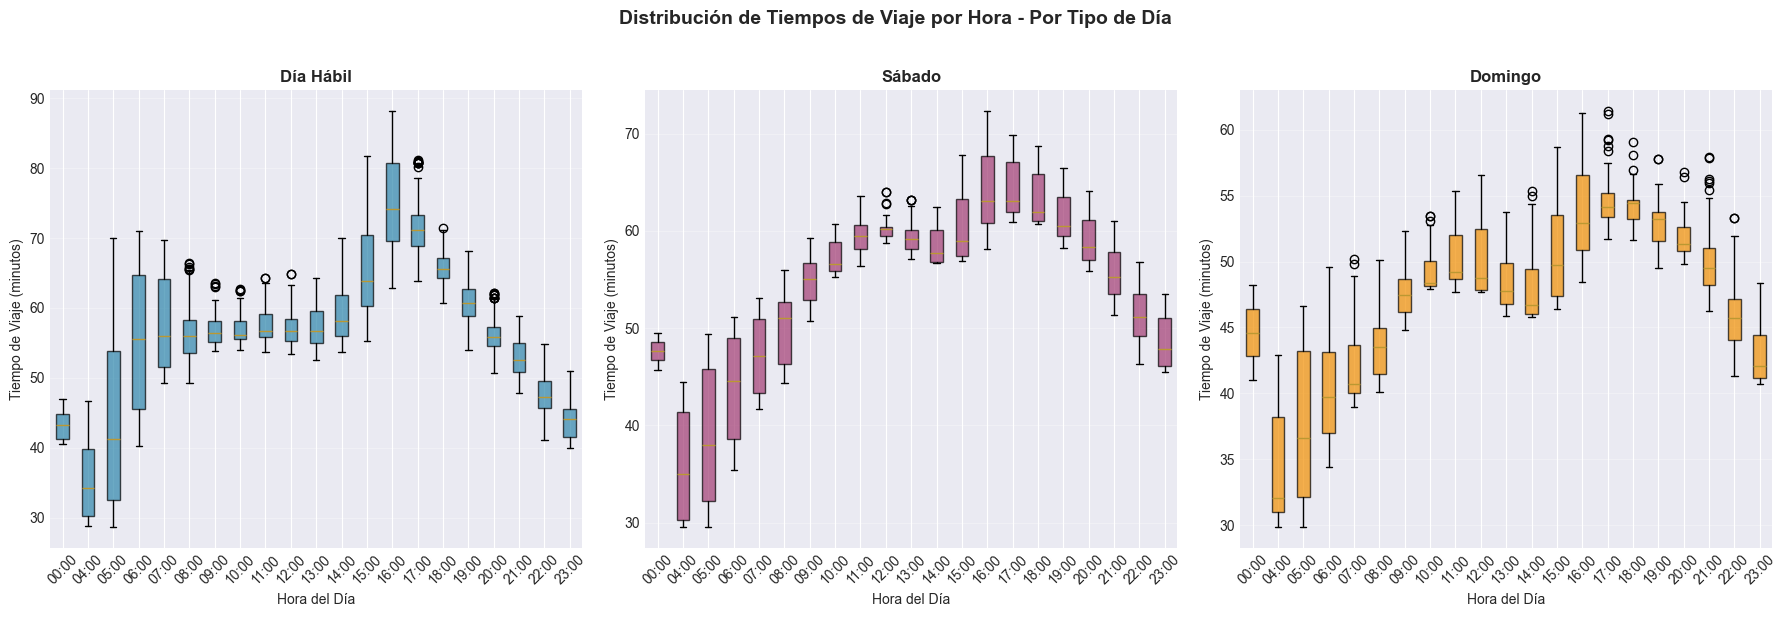

In [26]:
# Gráfico 5: Boxplot comparativo por tipo de día
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

tipos_dia = ['habil', 'sabado', 'domingo']
nombres_tipos = {'habil': 'Día Hábil', 'sabado': 'Sábado', 'domingo': 'Domingo'}

for idx, tipo_dia in enumerate(tipos_dia):
    df_tipo = df_resumen[df_resumen['tipo_dia'] == tipo_dia]
    
    if len(df_tipo) > 0:
        # Preparar datos para boxplot por hora
        data_boxplot = []
        labels_boxplot = []
        for hora in sorted(df_tipo['hora'].unique()):
            tiempos_hora = df_tipo[df_tipo['hora'] == hora]['tiempo_total_min'].values
            if len(tiempos_hora) > 0:
                data_boxplot.append(tiempos_hora)
                labels_boxplot.append(f"{hora:02d}:00")
        
        if len(data_boxplot) > 0:
            bp = axes[idx].boxplot(data_boxplot, labels=labels_boxplot, patch_artist=True)
            
            # Colorear
            color = colores.get(tipo_dia, 'gray')
            for patch in bp['boxes']:
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            
            axes[idx].set_title(nombres_tipos[tipo_dia], fontsize=12, fontweight='bold')
            axes[idx].set_xlabel('Hora del Día', fontsize=10)
            axes[idx].set_ylabel('Tiempo de Viaje (minutos)', fontsize=10)
            axes[idx].grid(True, alpha=0.3, axis='y')
            axes[idx].tick_params(axis='x', rotation=45)

plt.suptitle('Distribución de Tiempos de Viaje por Hora - Por Tipo de Día', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


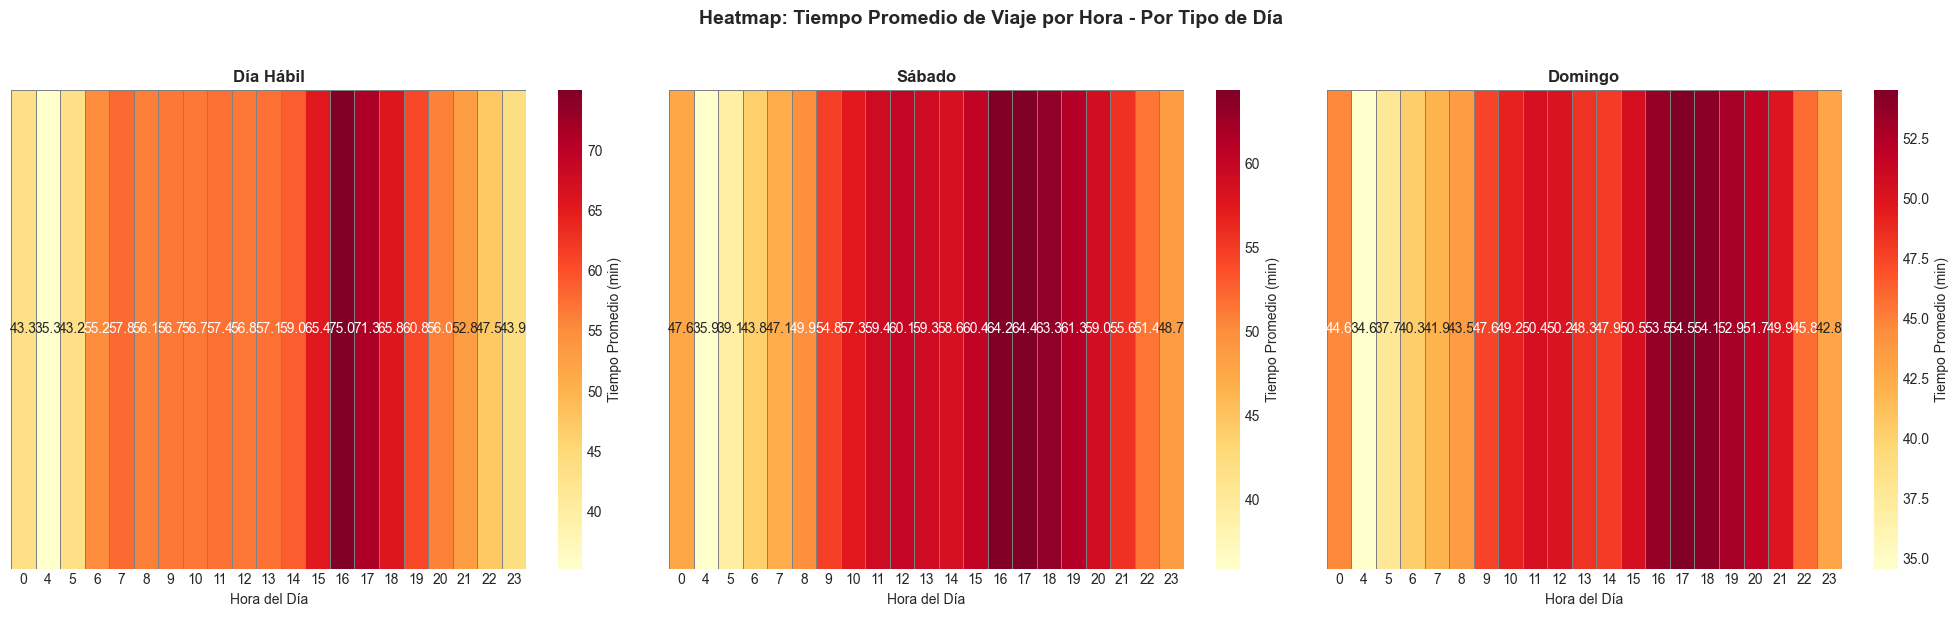

In [27]:
# Gráfico 6: Heatmap por tipo de día
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, tipo_dia in enumerate(tipos_dia):
    df_tipo = df_por_tipo_hora[df_por_tipo_hora['tipo_dia'] == tipo_dia]
    
    if len(df_tipo) > 0:
        # Crear matriz para el heatmap
        pivot_tipo = df_tipo.pivot_table(
            index='tipo_dia',
            columns='hora',
            values='tiempo_promedio',
            aggfunc='mean'
        )
        
        sns.heatmap(pivot_tipo, annot=True, fmt='.1f', cmap='YlOrRd',
                   cbar_kws={'label': 'Tiempo Promedio (min)'},
                   linewidths=0.5, linecolor='gray', ax=axes[idx])
        
        axes[idx].set_title(nombres_tipos[tipo_dia], fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Hora del Día', fontsize=10)
        axes[idx].set_ylabel('')
        axes[idx].set_yticklabels([])

plt.suptitle('Heatmap: Tiempo Promedio de Viaje por Hora - Por Tipo de Día', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


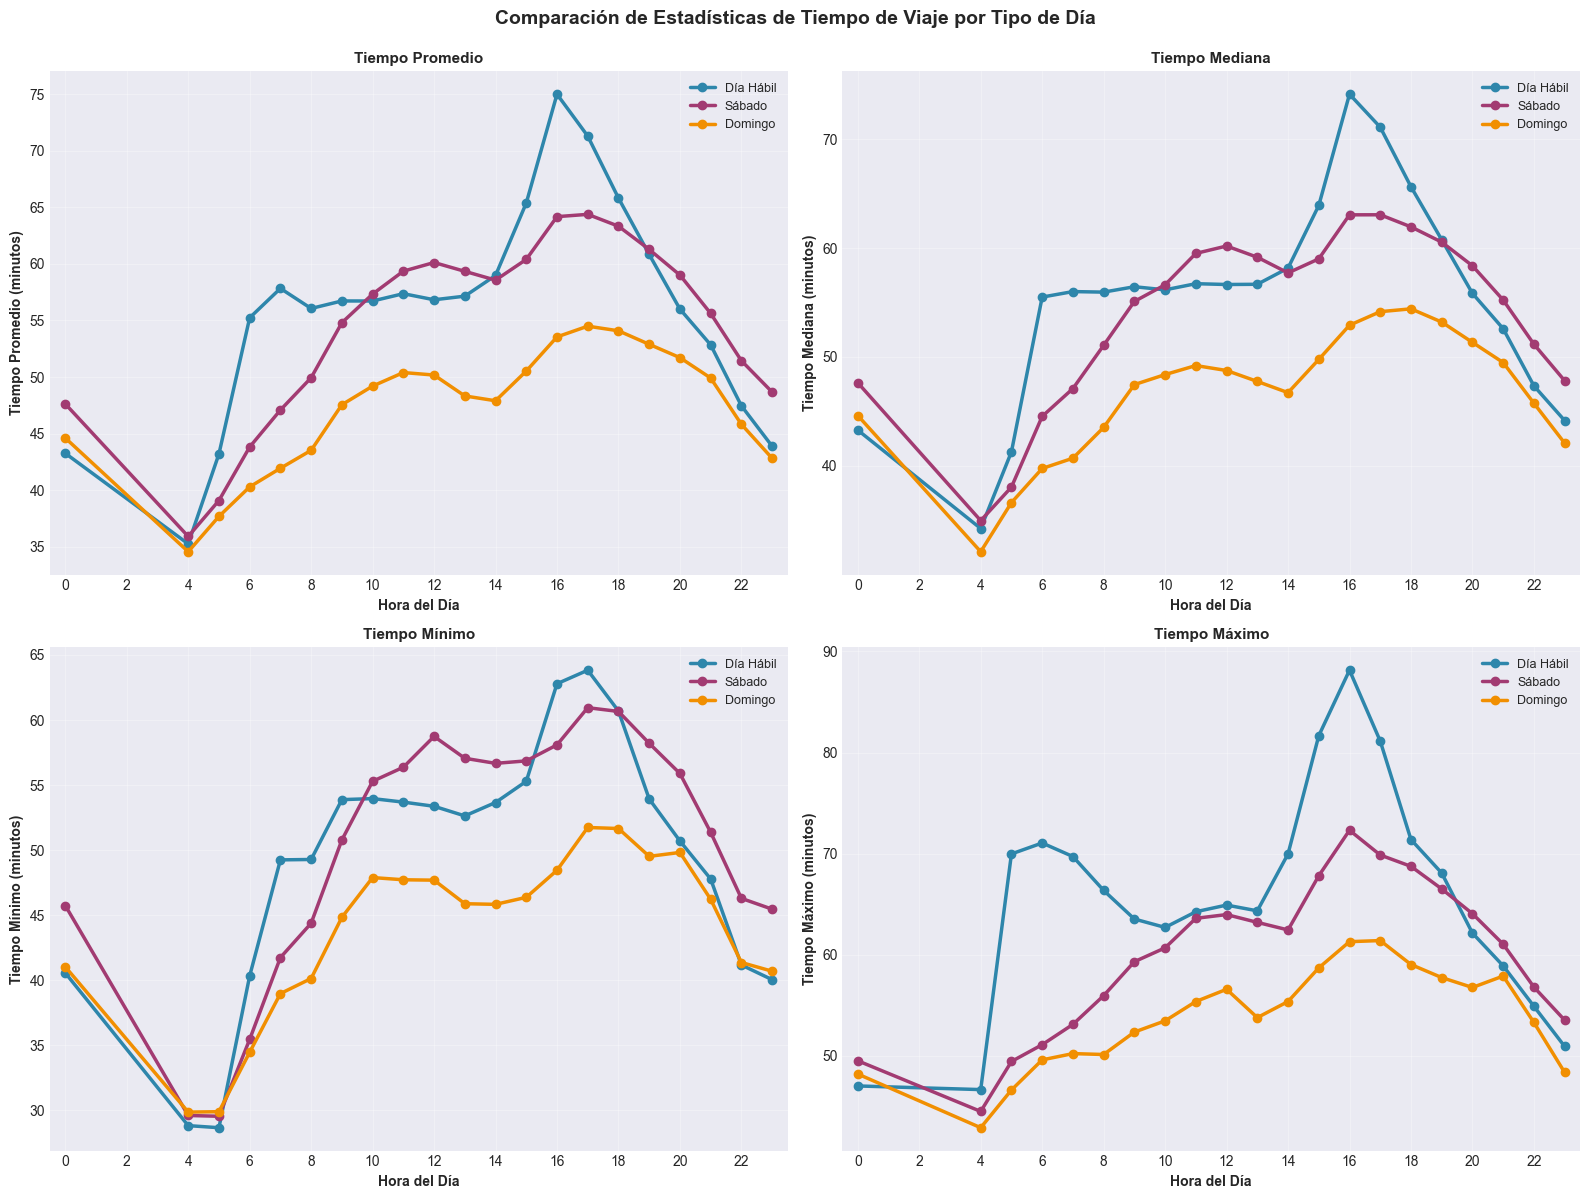

In [28]:
# Gráfico 7: Comparación de estadísticas por tipo de día
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Estadísticas a comparar
estadisticas = ['tiempo_promedio', 'tiempo_mediana', 'tiempo_min', 'tiempo_max']
titulos = ['Tiempo Promedio', 'Tiempo Mediana', 'Tiempo Mínimo', 'Tiempo Máximo']

for idx, (stat, titulo) in enumerate(zip(estadisticas, titulos)):
    ax = axes[idx // 2, idx % 2]
    
    for tipo_dia in tipos_dia:
        df_tipo = df_por_tipo_hora[df_por_tipo_hora['tipo_dia'] == tipo_dia]
        if len(df_tipo) > 0:
            nombre_tipo = nombres_tipos[tipo_dia]
            ax.plot(df_tipo['hora'], df_tipo[stat], 
                   marker='o', label=nombre_tipo, 
                   linewidth=2.5, markersize=6, 
                   color=colores.get(tipo_dia, 'gray'))
    
    ax.set_xlabel('Hora del Día', fontsize=10, fontweight='bold')
    ax.set_ylabel(f'{titulo} (minutos)', fontsize=10, fontweight='bold')
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(-0.5, 23.5)

plt.suptitle('Comparación de Estadísticas de Tiempo de Viaje por Tipo de Día', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## 5. Resumen Estadístico


In [29]:
# Resumen estadístico por tipo de día
print("="*60)
print("RESUMEN ESTADÍSTICO POR TIPO DE DÍA")
print("="*60)

for tipo_dia in tipos_dia:
    df_tipo = df_resumen[df_resumen['tipo_dia'] == tipo_dia]
    if len(df_tipo) > 0:
        print(f"\n{nombres_tipos[tipo_dia].upper()}:")
        print(f"  Total de viajes: {len(df_tipo):,}")
        print(f"  Tiempo promedio: {df_tipo['tiempo_total_min'].mean():.2f} minutos")
        print(f"  Tiempo mediana: {df_tipo['tiempo_total_min'].median():.2f} minutos")
        print(f"  Tiempo mínimo: {df_tipo['tiempo_total_min'].min():.2f} minutos")
        print(f"  Tiempo máximo: {df_tipo['tiempo_total_min'].max():.2f} minutos")
        print(f"  Desviación estándar: {df_tipo['tiempo_total_min'].std():.2f} minutos")

print("\n" + "="*60)
print("RESUMEN POR HORA DEL DÍA (TODOS LOS TIPOS DE DÍA)")
print("="*60)

resumen_hora = df_resumen.groupby('hora')['tiempo_total_min'].agg([
    'count', 'mean', 'median', 'min', 'max', 'std'
]).round(2)
resumen_hora.columns = ['Num_Viajes', 'Promedio', 'Mediana', 'Min', 'Max', 'Std']
print(resumen_hora)


RESUMEN ESTADÍSTICO POR TIPO DE DÍA

DÍA HÁBIL:
  Total de viajes: 12,010
  Tiempo promedio: 56.48 minutos
  Tiempo mediana: 56.60 minutos
  Tiempo mínimo: 28.66 minutos
  Tiempo máximo: 88.14 minutos
  Desviación estándar: 10.26 minutos

SÁBADO:
  Total de viajes: 2,402
  Tiempo promedio: 54.68 minutos
  Tiempo mediana: 57.05 minutos
  Tiempo mínimo: 29.54 minutos
  Tiempo máximo: 72.31 minutos
  Desviación estándar: 8.71 minutos

DOMINGO:
  Total de viajes: 2,402
  Tiempo promedio: 47.37 minutos
  Tiempo mediana: 48.11 minutos
  Tiempo mínimo: 29.86 minutos
  Tiempo máximo: 61.40 minutos
  Desviación estándar: 6.12 minutos

RESUMEN POR HORA DEL DÍA (TODOS LOS TIPOS DE DÍA)
      Num_Viajes  Promedio  Mediana    Min    Max    Std
hora                                                    
0             14     44.08    44.32  40.56  49.51   2.87
4            840     35.25    32.28  28.82  46.66   5.02
5            840     41.83    40.64  28.66  69.97  10.18
6            840     51.47    4

In [30]:
# Resumen por tipo de día y hora
print("\n" + "="*60)
print("RESUMEN POR TIPO DE DÍA Y HORA")
print("="*60)

resumen_tipo_hora = df_resumen.groupby(['tipo_dia', 'hora'])['tiempo_total_min'].agg([
    'count', 'mean', 'median', 'min', 'max'
]).round(2)
resumen_tipo_hora.columns = ['Num_Viajes', 'Promedio', 'Mediana', 'Min', 'Max']

# Mostrar para horas clave (mañana, mediodía, tarde, noche)
horas_clave = [6, 8, 12, 14, 18, 20]
for hora in horas_clave:
    if hora in resumen_tipo_hora.index.get_level_values('hora'):
        print(f"\nHora {hora:02d}:00:")
        print(resumen_tipo_hora.loc[(slice(None), hora), :])



RESUMEN POR TIPO DE DÍA Y HORA

Hora 06:00:
               Num_Viajes  Promedio  Mediana    Min    Max
tipo_dia hora                                             
domingo  6            120     40.29    39.75  34.46  49.60
habil    6            600     55.24    55.50  40.33  71.05
sabado   6            120     43.82    44.54  35.45  51.10

Hora 08:00:
               Num_Viajes  Promedio  Mediana    Min    Max
tipo_dia hora                                             
domingo  8            120     43.52    43.52  40.13  50.13
habil    8            600     56.06    55.95  49.28  66.36
sabado   8            120     49.94    51.06  44.38  55.95

Hora 12:00:
               Num_Viajes  Promedio  Mediana    Min    Max
tipo_dia hora                                             
domingo  12           120     50.18    48.75  47.69  56.58
habil    12           600     56.83    56.65  53.37  64.91
sabado   12           120     60.12    60.18  58.74  63.97

Hora 14:00:
               Num_Viajes  Prom